In [10]:
# Step 1: Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [11]:
#pip install -r requirements.txt

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd

file_path = '/content/drive/MyDrive/MS_AIML/5_QM_640_Capstone_Project/default_of_credit_card_clients/default_of_credit_card_clients_csv.csv'

# Read dataset (space-delimited)
df = pd.read_csv(file_path)

print(df.head())
print(df.info())

  Unnamed: 0         X1   X2         X3        X4   X5     X6     X7     X8  \
0         ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3   
1          1      20000    2          2         1   24      2      2     -1   
2          2     120000    2          2         2   26     -1      2      0   
3          3      90000    2          2         2   34      0      0      0   
4          4      50000    2          2         1   37      0      0      0   

      X9  ...        X15        X16        X17       X18       X19       X20  \
0  PAY_4  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3   
1     -1  ...          0          0          0         0       689         0   
2      0  ...       3272       3455       3261         0      1000      1000   
3      0  ...      14331      14948      15549      1518      1500      1000   
4      0  ...      28314      28959      29547      2000      2019      1200   

        X21       X22       X23             

### Data Pre-processing

In [14]:
columns = [
    "ID","LIMIT_BAL","SEX","EDUCATION","MARRIAGE","AGE",
    "PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6",
    "BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6",
    "PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6",
    "DEFAULT_NEXT_MONTH"
]

df.columns = columns


# Remove duplicate header row
df = df.iloc[1:].copy()

print(df["SEX"].head(10))
print(df["SEX"].unique())

print(df.shape)
df.columns = columns
print(df.head())


1     2
2     2
3     2
4     2
5     1
6     1
7     1
8     2
9     2
10    1
Name: SEX, dtype: object
['2' '1']
(30000, 25)
  ID LIMIT_BAL SEX EDUCATION MARRIAGE AGE PAY_0 PAY_2 PAY_3 PAY_4  ...  \
1  1     20000   2         2        1  24     2     2    -1    -1  ...   
2  2    120000   2         2        2  26    -1     2     0     0  ...   
3  3     90000   2         2        2  34     0     0     0     0  ...   
4  4     50000   2         2        1  37     0     0     0     0  ...   
5  5     50000   1         2        1  57    -1     0    -1     0  ...   

  BILL_AMT4 BILL_AMT5 BILL_AMT6 PAY_AMT1 PAY_AMT2 PAY_AMT3 PAY_AMT4 PAY_AMT5  \
1         0         0         0        0      689        0        0        0   
2      3272      3455      3261        0     1000     1000     1000        0   
3     14331     14948     15549     1518     1500     1000     1000     1000   
4     28314     28959     29547     2000     2019     1200     1100     1069   
5     20940     19146     19

In [15]:
import pandas as pd

# Convert all columns except ID to numeric
for col in df.columns:
    if col != "ID":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Inspect categories BEFORE cleaning
print(df.dtypes)

print("SEX:", sorted(df["SEX"].unique()))
print("EDUCATION:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE:", sorted(df["MARRIAGE"].unique()))
print("PAY_0:", sorted(df["PAY_0"].unique()))

# ==========================================
# CLEAN CATEGORICAL VARIABLES
# ==========================================

# EDUCATION:
# 0, 5, 6 -> Other (4)
df["EDUCATION"] = df["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

# MARRIAGE:
# 0 -> Other (3)
df["MARRIAGE"] = df["MARRIAGE"].replace({
    0: 3
})

# SEX:
# Original coding:
# 1 = Male
# 2 = Female

df["SEX"] = df["SEX"].map({
    1: 0,   # Male
    2: 1    # Female
})

# ==========================================
# VERIFICATION
# ==========================================

print("\nAfter Cleaning")

print("SEX:", sorted(df["SEX"].dropna().unique()))
print("EDUCATION:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE:", sorted(df["MARRIAGE"].unique()))

print("\nMissing Values")
print("SEX:", df["SEX"].isnull().sum())
print("EDUCATION:", df["EDUCATION"].isnull().sum())
print("MARRIAGE:", df["MARRIAGE"].isnull().sum())

# Verify repayment status ranges
for col in ["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"]:
    print(col, sorted(df[col].unique()))

ID                    object
LIMIT_BAL              int64
SEX                    int64
EDUCATION              int64
MARRIAGE               int64
AGE                    int64
PAY_0                  int64
PAY_2                  int64
PAY_3                  int64
PAY_4                  int64
PAY_5                  int64
PAY_6                  int64
BILL_AMT1              int64
BILL_AMT2              int64
BILL_AMT3              int64
BILL_AMT4              int64
BILL_AMT5              int64
BILL_AMT6              int64
PAY_AMT1               int64
PAY_AMT2               int64
PAY_AMT3               int64
PAY_AMT4               int64
PAY_AMT5               int64
PAY_AMT6               int64
DEFAULT_NEXT_MONTH     int64
dtype: object
SEX: [np.int64(1), np.int64(2)]
EDUCATION: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
PAY_0: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), n

- Confirms data types.

- Shows unique values for categorical variables.

- Cleans anomalies in EDUCATION (values 0, 5, 6 → “Others”) and MARRIAGE (value 0 → “Others”).

- Maps SEX into readable labels.

- Validates repayment status ranges (−2 to 9).

In [16]:
print(df.isnull().sum())

ID                    0
LIMIT_BAL             0
SEX                   0
EDUCATION             0
MARRIAGE              0
AGE                   0
PAY_0                 0
PAY_2                 0
PAY_3                 0
PAY_4                 0
PAY_5                 0
PAY_6                 0
BILL_AMT1             0
BILL_AMT2             0
BILL_AMT3             0
BILL_AMT4             0
BILL_AMT5             0
BILL_AMT6             0
PAY_AMT1              0
PAY_AMT2              0
PAY_AMT3              0
PAY_AMT4              0
PAY_AMT5              0
PAY_AMT6              0
DEFAULT_NEXT_MONTH    0
dtype: int64


- No NULL Values in Dataset

In [17]:
print(df.duplicated().sum())

0


- No Duplicate values in dataset

In [18]:
num_cols = [
    'LIMIT_BAL',
    'BILL_AMT1','BILL_AMT2','BILL_AMT3',
    'BILL_AMT4','BILL_AMT5','BILL_AMT6',
    'PAY_AMT1','PAY_AMT2','PAY_AMT3',
    'PAY_AMT4','PAY_AMT5','PAY_AMT6'
]

# Ensure numeric types
df[num_cols] = df[num_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

# Outlier Detection
from scipy import stats

outlier_counts = {
    col: (abs(stats.zscore(df[col])) > 3).sum()
    for col in num_cols
}

print("Outlier Counts Per Column:")
print(outlier_counts)

# Optional: Percentages
outlier_pct = {
    col: round(
        100 * ((abs(stats.zscore(df[col])) > 3).sum()) / len(df),
        2
    )
    for col in num_cols
}

print("\nOutlier Percentages:")
print(outlier_pct)

outlier_summary = pd.DataFrame({
    "Outlier_Count": outlier_counts,
    "Outlier_Percentage": outlier_pct
})

print(outlier_summary)

Outlier Counts Per Column:
{'LIMIT_BAL': np.int64(130), 'BILL_AMT1': np.int64(686), 'BILL_AMT2': np.int64(670), 'BILL_AMT3': np.int64(661), 'BILL_AMT4': np.int64(680), 'BILL_AMT5': np.int64(651), 'BILL_AMT6': np.int64(651), 'PAY_AMT1': np.int64(390), 'PAY_AMT2': np.int64(307), 'PAY_AMT3': np.int64(362), 'PAY_AMT4': np.int64(396), 'PAY_AMT5': np.int64(414), 'PAY_AMT6': np.int64(439)}

Outlier Percentages:
{'LIMIT_BAL': np.float64(0.43), 'BILL_AMT1': np.float64(2.29), 'BILL_AMT2': np.float64(2.23), 'BILL_AMT3': np.float64(2.2), 'BILL_AMT4': np.float64(2.27), 'BILL_AMT5': np.float64(2.17), 'BILL_AMT6': np.float64(2.17), 'PAY_AMT1': np.float64(1.3), 'PAY_AMT2': np.float64(1.02), 'PAY_AMT3': np.float64(1.21), 'PAY_AMT4': np.float64(1.32), 'PAY_AMT5': np.float64(1.38), 'PAY_AMT6': np.float64(1.46)}
           Outlier_Count  Outlier_Percentage
LIMIT_BAL            130                0.43
BILL_AMT1            686                2.29
BILL_AMT2            670                2.23
BILL_AMT3       

In [19]:
# ==========================================
# FEATURE ENGINEERING (8 Engineered Features)
# ==========================================

import numpy as np

# 1. TOTAL_BILL
df['TOTAL_BILL'] = df[[f'BILL_AMT{i}' for i in range(1,7)]].sum(axis=1)

# 2. TOTAL_PAY
df['TOTAL_PAY'] = df[[f'PAY_AMT{i}' for i in range(1,7)]].sum(axis=1)

# 3. AVG_UTIL_RATIO
util_ratios = []

for i in range(1,7):
    ratio = np.where(
        df['LIMIT_BAL'] > 1e-6,
        df[f'BILL_AMT{i}'] / df['LIMIT_BAL'],
        0
    )
    util_ratios.append(np.clip(ratio, 0, 5))

df['AVG_UTIL_RATIO'] = np.mean(util_ratios, axis=0)

# 4. AVG_PAY_RATIO
pay_ratios = []

for i in range(1,7):
    ratio = np.where(
        df[f'BILL_AMT{i}'] > 1e-6,
        df[f'PAY_AMT{i}'] / df[f'BILL_AMT{i}'],
        0
    )
    pay_ratios.append(np.clip(ratio, 0, 5))

df['AVG_PAY_RATIO'] = np.mean(pay_ratios, axis=0)

# 5. BILL_TREND
df['BILL_TREND'] = df['BILL_AMT6'] - df['BILL_AMT1']

# 6. PAY_TREND
df['PAY_TREND'] = df['PAY_AMT6'] - df['PAY_AMT1']

# 7. MISSED_PAYMENTS
df['MISSED_PAYMENTS'] = (
    df[[f'PAY_AMT{i}' for i in range(1,7)]] == 0
).sum(axis=1)

# 8. OVERPAYMENTS
df['OVERPAYMENTS'] = (
    df[[f'PAY_AMT{i}' for i in range(1,7)]].values >
    df[[f'BILL_AMT{i}' for i in range(1,7)]].values
).sum(axis=1)

# Replace any residual inf values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.fillna(0)

# ==========================================
# VERIFY ENGINEERED FEATURES
# ==========================================

engineered_features = [
    'TOTAL_BILL',
    'TOTAL_PAY',
    'AVG_UTIL_RATIO',
    'AVG_PAY_RATIO',
    'BILL_TREND',
    'PAY_TREND',
    'MISSED_PAYMENTS',
    'OVERPAYMENTS'
]

print("\nEngineered Features Created:")
print(engineered_features)

print("\nPreview:")
print(df[engineered_features].head())

print("\nDataset Shape After Feature Engineering:")
print(df.shape)

print("Number of Features:", len(df.columns)-1)


Engineered Features Created:
['TOTAL_BILL', 'TOTAL_PAY', 'AVG_UTIL_RATIO', 'AVG_PAY_RATIO', 'BILL_TREND', 'PAY_TREND', 'MISSED_PAYMENTS', 'OVERPAYMENTS']

Preview:
   TOTAL_BILL  TOTAL_PAY  AVG_UTIL_RATIO  AVG_PAY_RATIO  BILL_TREND  \
1        7704        689        0.064200       0.037019       -3913   
2       17077       5000        0.023718       0.311916         579   
3      101653      11018        0.188246       0.115141      -13690   
4      231334       8388        0.771113       0.036396      -17443   
5      109339      59049        0.364463       1.002072       10514   

   PAY_TREND  MISSED_PAYMENTS  OVERPAYMENTS  
1          0                5             0  
2       2000                2             0  
3       3482                0             0  
4      -1000                0             0  
5      -1321                0             1  

Dataset Shape After Feature Engineering:
(30000, 33)
Number of Features: 32


In [20]:
#Rename Taregt Column

df = df.rename(
    columns={
        "DEFAULT_NEXT_MONTH":"CreditRisk"
    }
)

In [21]:
#Train/Test split
from sklearn.model_selection import train_test_split

# Target variable: DEFAULT_NEXT_MONTH (already binary: 0 = Non-default, 1 = Default)
X = df.drop(columns=["ID","CreditRisk"])   # drop ID and target
y = df["CreditRisk"]

# Check distribution
print("Class distribution:\n", y.value_counts())

# Train/Test split (stratified to preserve class distribution ~22% default)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

Class distribution:
 CreditRisk
0    23364
1     6636
Name: count, dtype: int64


In [22]:
# Handle Outliers
# Scale numeric variables
from sklearn.preprocessing import RobustScaler

# Continuous variables
numeric_cols = [
'LIMIT_BAL',
'BILL_AMT1','BILL_AMT2','BILL_AMT3',
'BILL_AMT4','BILL_AMT5','BILL_AMT6',
'PAY_AMT1','PAY_AMT2','PAY_AMT3',
'PAY_AMT4','PAY_AMT5','PAY_AMT6',
'TOTAL_BILL',
'TOTAL_PAY',
'AVG_UTIL_RATIO',
'AVG_PAY_RATIO',
'BILL_TREND',
'PAY_TREND'
]

# Initialize RobustScaler (less sensitive to outliers)
scaler = RobustScaler()

# Fit ONLY on training data
X_train[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Apply same scaler to test data
X_test[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

# Quick check: scaled summary
print("Scaling completed successfully.")
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)


Scaling completed successfully.
Training set shape: (21000, 31)
Test set shape: (9000, 31)


In [23]:
print(X_train[numeric_cols].dtypes)
print(X_train[numeric_cols].head())

LIMIT_BAL         float64
BILL_AMT1         float64
BILL_AMT2         float64
BILL_AMT3         float64
BILL_AMT4         float64
BILL_AMT5         float64
BILL_AMT6         float64
PAY_AMT1          float64
PAY_AMT2          float64
PAY_AMT3          float64
PAY_AMT4          float64
PAY_AMT5          float64
PAY_AMT6          float64
TOTAL_BILL        float64
TOTAL_PAY         float64
AVG_UTIL_RATIO    float64
AVG_PAY_RATIO     float64
BILL_TREND        float64
PAY_TREND         float64
dtype: object
       LIMIT_BAL  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  \
11019   0.105263   2.106470   2.212479   2.362316   2.569009   2.859506   
1711   -0.210526   0.096888   0.194806   0.388584   0.622973   0.670019   
4619   -0.315789   0.810292   0.888649   0.772334   0.506549   0.497744   
5483   -0.631579  -0.235072  -0.308042  -0.335559  -0.363278  -0.373344   
26188  -0.473684  -0.349716  -0.309514  -0.349169  -0.363278  -0.373344   

       BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY

CreditRisk
0    23364
1     6636
Name: count, dtype: int64
CreditRisk
0    0.7788
1    0.2212
Name: count, dtype: float64


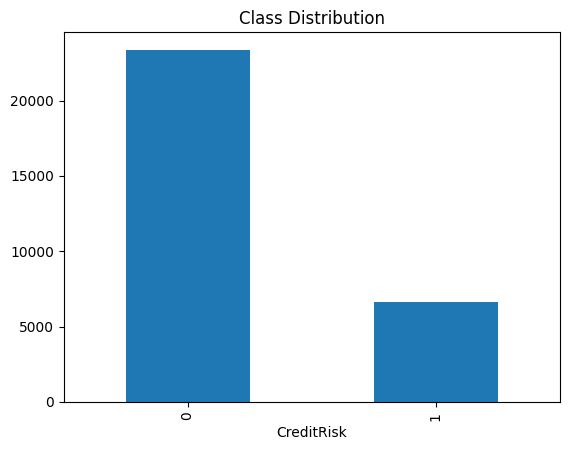

In [24]:
#Class Imbalance Check
import matplotlib.pyplot as plt

# Target distribution
class_counts = df['CreditRisk'].value_counts()
print(class_counts)

# Percentage distribution
print(class_counts / len(df))

# Quick bar plot
class_counts.plot(kind='bar', title='Class Distribution')
plt.show()


In [25]:
import numpy as np
import pandas as pd

# Force all columns to numeric (anything non-numeric becomes NaN)
df_numeric = df.apply(pd.to_numeric, errors="coerce")

# Check for infinities
inf_mask = np.isinf(df_numeric.to_numpy())
print("Total infinities:", inf_mask.sum())
#print("Infinities per column:\n", pd.Series(inf_mask.sum(axis=0), index=df_numeric.columns))

# Check for NaNs
nan_mask = np.isnan(df_numeric.to_numpy())
print("Total NaNs:", nan_mask.sum())
#print("NaNs per column:\n", pd.Series(nan_mask.sum(axis=0), index=df_numeric.columns))

# Identify problematic rows
bad_rows = np.where(inf_mask.any(axis=1) | nan_mask.any(axis=1))[0]
print("Rows with issues:", bad_rows[:20])  # show first 20


Total infinities: 0
Total NaNs: 0
Rows with issues: []


In [26]:
print("Missing values per column:\n", X.isnull().sum())


Missing values per column:
 LIMIT_BAL          0
SEX                0
EDUCATION          0
MARRIAGE           0
AGE                0
PAY_0              0
PAY_2              0
PAY_3              0
PAY_4              0
PAY_5              0
PAY_6              0
BILL_AMT1          0
BILL_AMT2          0
BILL_AMT3          0
BILL_AMT4          0
BILL_AMT5          0
BILL_AMT6          0
PAY_AMT1           0
PAY_AMT2           0
PAY_AMT3           0
PAY_AMT4           0
PAY_AMT5           0
PAY_AMT6           0
TOTAL_BILL         0
TOTAL_PAY          0
AVG_UTIL_RATIO     0
AVG_PAY_RATIO      0
BILL_TREND         0
PAY_TREND          0
MISSED_PAYMENTS    0
OVERPAYMENTS       0
dtype: int64


### Base Model

In [27]:
# Step 6: Baseline Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

- Reasoning: Logistic Regression is a baseline, interpretable, widely used in credit scoring.

- Assumptions: Linear relationship between predictors and log‑odds of default.

- Limitations: Sensitive to multicollinearity, may underperform on nonlinear patterns.

In [28]:
# Step 7: Evaluation
from sklearn.metrics import accuracy_score

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
acc = accuracy_score(y_test, y_pred)
print("\nAccuracy:", round(acc, 2))

Confusion Matrix:
 [[6748  261]
 [1486  505]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.96      0.89      7009
           1       0.66      0.25      0.37      1991

    accuracy                           0.81      9000
   macro avg       0.74      0.61      0.63      9000
weighted avg       0.78      0.81      0.77      9000


Accuracy: 0.81


### EDAs

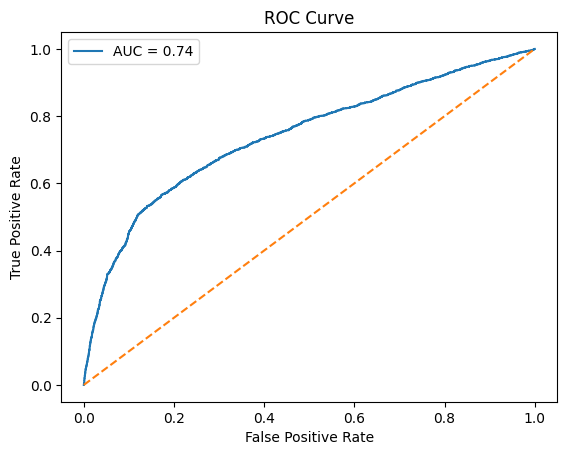

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


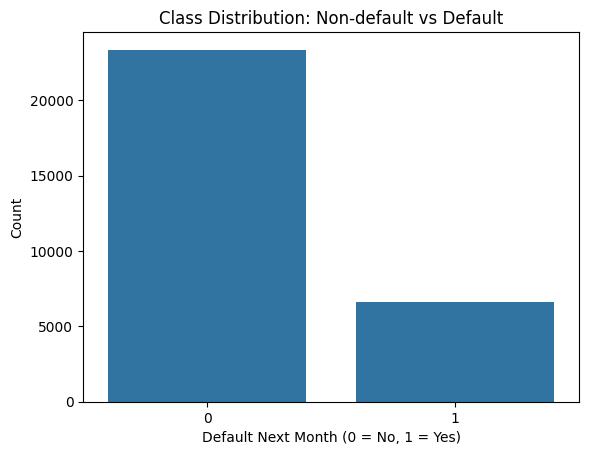

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Class balance
sns.countplot(x="CreditRisk", data=df)
plt.title("Class Distribution: Non-default vs Default")
plt.xlabel("Default Next Month (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


- Class Distribution Bar Chart: Shows imbalance (≈22% default vs 78% non‑default). This is important for motivating class imbalance handling.

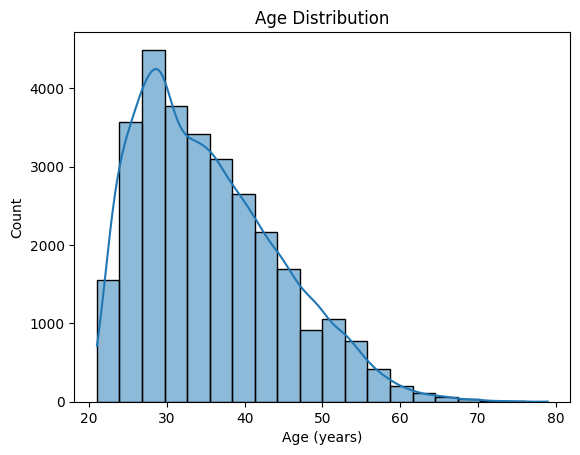

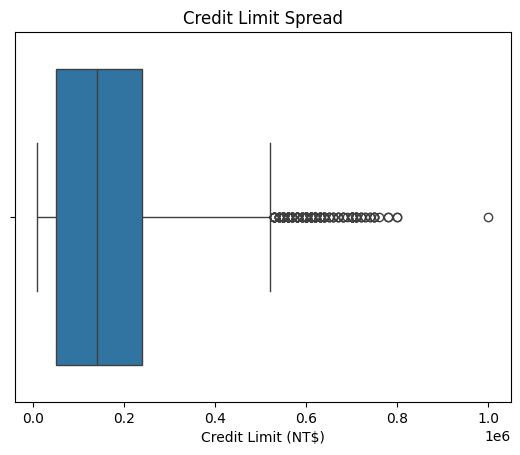

In [31]:
# Histogram for Age
sns.histplot(df["AGE"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.show()

# Boxplot for Credit Amount
sns.boxplot(x=df["LIMIT_BAL"])
plt.title("Credit Limit Spread")
plt.xlabel("Credit Limit (NT$)")
plt.show()


- Age Histogram: Reveals right‑skewed distribution; younger customers dominate, older customers taper off. Supports demographic analysis.

- Credit Limit Boxplot: Highlights variability and extreme outliers in credit limits. Outliers may distort models if not handled.

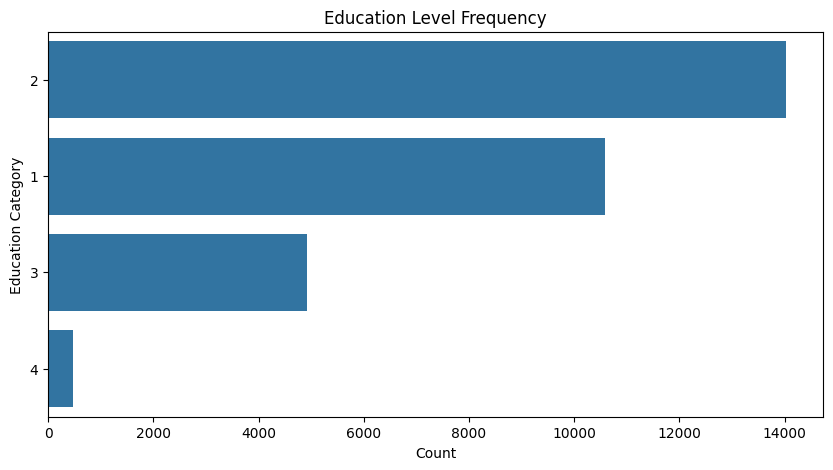

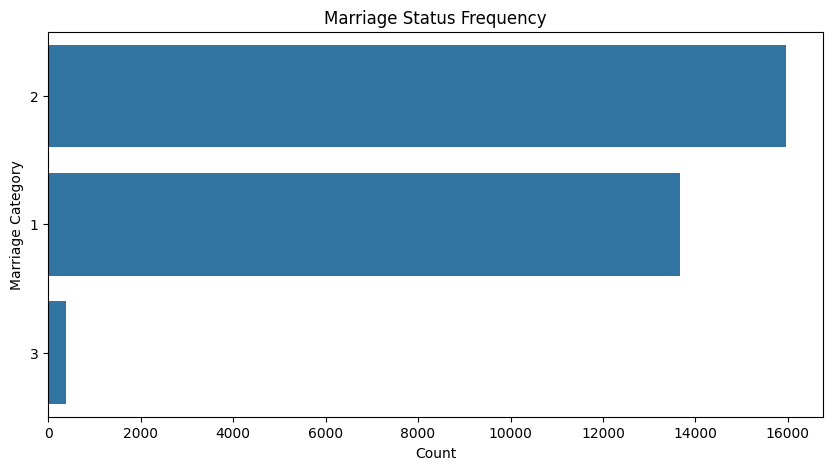

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example: Bar plot for Education levels
plt.figure(figsize=(10,5))
sns.countplot(y="EDUCATION", data=df, order=df["EDUCATION"].value_counts().index)
plt.title("Education Level Frequency")
plt.xlabel("Count")
plt.ylabel("Education Category")
plt.show()

# Example: Bar plot for Marriage status
plt.figure(figsize=(10,5))
sns.countplot(y="MARRIAGE", data=df, order=df["MARRIAGE"].value_counts().index)
plt.title("Marriage Status Frequency")
plt.xlabel("Count")
plt.ylabel("Marriage Category")
plt.show()

- Education Frequency Chart: Most customers are in category 2 (graduate level). Rare categories (0, 4, 5, 6) may need grouping.

- Marriage Status Frequency Chart: Majority are category 2 (married), followed by category 1 (single). Rare categories again suggest grouping.

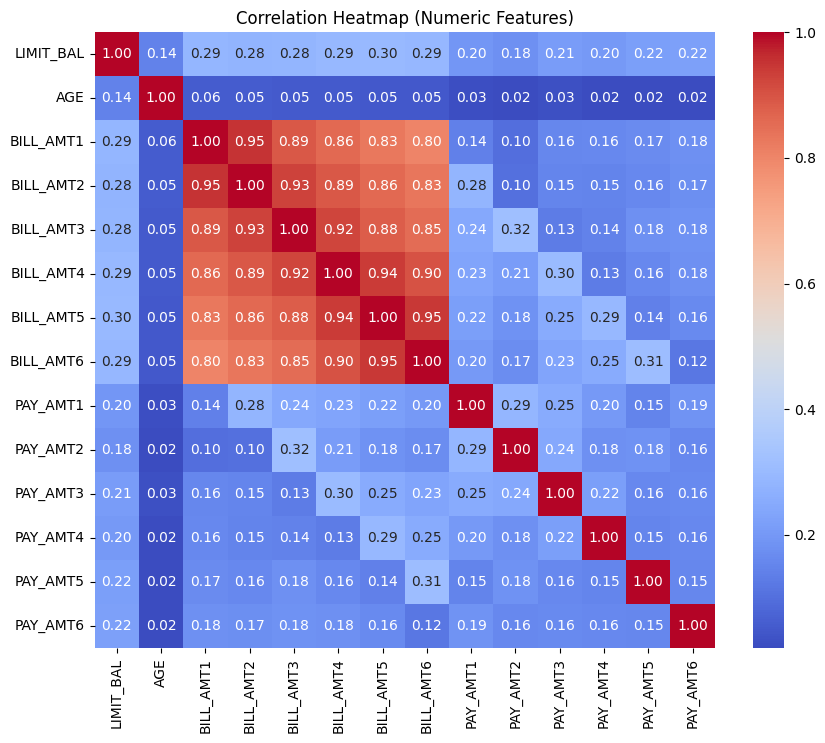

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation matrix for numeric features
numeric_cols = ["LIMIT_BAL","AGE"] + \
               [f"BILL_AMT{i}" for i in range(1,7)] + \
               [f"PAY_AMT{i}" for i in range(1,7)]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()


- Correlation Heatmap: Strong correlations among consecutive bill amounts; moderate correlations among payments. Helps identify redundant features.

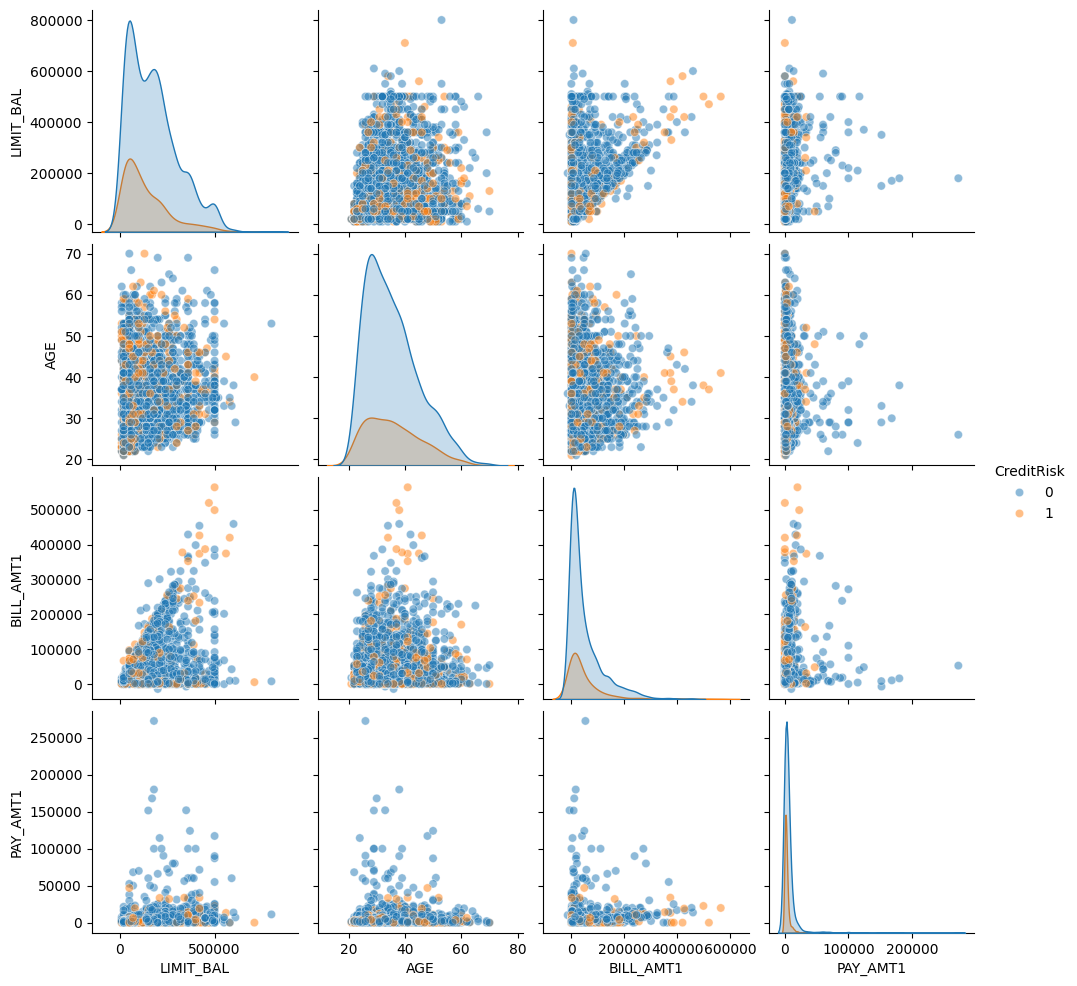

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sample subset for speed
df_sample = df.sample(2000, random_state=42)

# Shortlist of key numeric features
selected_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "CreditRisk"]

sns.pairplot(df_sample[selected_cols],
             hue="CreditRisk",
             diag_kind="kde",
             plot_kws={"alpha":0.5})
plt.show()

- Pair Plot: Shows relationships between LIMIT_BAL, AGE, BILL_AMT1, PAY_AMT1, color‑coded by default status. Reveals separation patterns and overlap between classes.

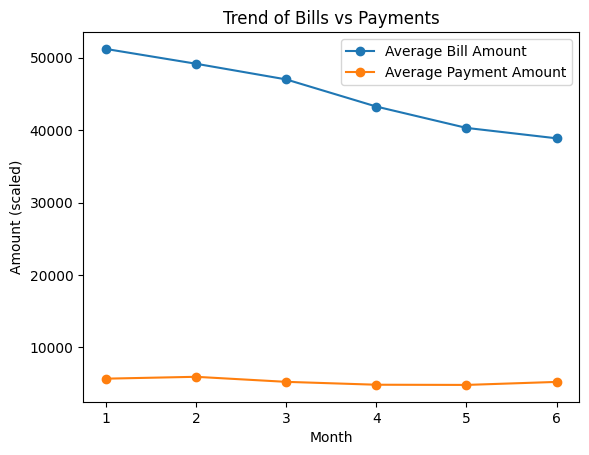

In [35]:
import matplotlib.pyplot as plt

# Average bill and payment amounts across months
avg_bills = [df[f'BILL_AMT{i}'].mean() for i in range(1,7)]
avg_pays  = [df[f'PAY_AMT{i}'].mean() for i in range(1,7)]

months = range(1,7)

plt.plot(months, avg_bills, marker='o', label='Average Bill Amount')
plt.plot(months, avg_pays, marker='o', label='Average Payment Amount')
plt.xlabel("Month")
plt.ylabel("Amount (scaled)")
plt.title("Trend of Bills vs Payments")
plt.legend()
plt.show()


Trend of Bills vs Payments (Line Plot)
- What it shows: Average bill amounts remain relatively flat across months, while average payments are consistently higher and more variable.

- Insight: This suggests that, on average, customers are paying more than their billed amounts, which could indicate proactive repayment or overpayment behavior.

- Link to research questions: Supports the question on repayment consistency and highlights a potential anomaly — payments exceeding bills — which may influence default prediction.

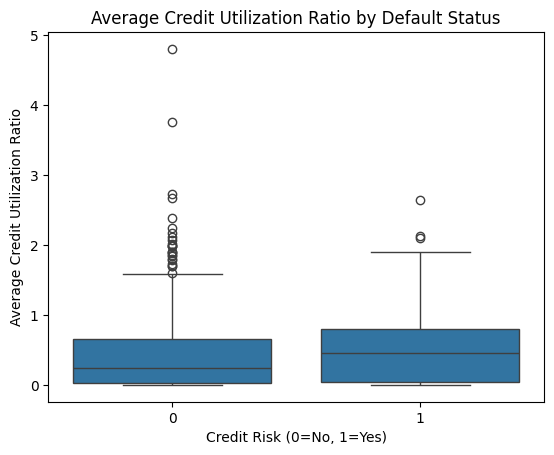

In [36]:
import seaborn as sns

sns.boxplot(x="CreditRisk", y="AVG_UTIL_RATIO", data=df)
plt.title("Average Credit Utilization Ratio by Default Status")
plt.xlabel("Credit Risk (0=No, 1=Yes)")
plt.ylabel("Average Credit Utilization Ratio")
plt.show()


Credit Utilization vs Default (Box/Scatter Plot)
- What it shows: Utilization ratios (bill amount relative to credit limit) are spread across both non‑defaulters and defaulters, but defaulters tend to cluster at higher utilization levels.

- Insight: High utilization is a known risk factor — customers who consistently use a large portion of their credit limit are more likely to default.

- Link to research questions: Directly addresses predictors of default, showing utilization ratio as a strong behavioral signal.